## AI vs Human ext Classification

## Python libraries

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from datasets import Dataset
import torch
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


Load the DataFrame

In [20]:
data = pd.read_csv('AI_vs_Human_Text_Classification_Benchmark.csv')


## Data transformation

In [21]:
df = data[['Raw_Text', 'Label']].copy()

EXPLORATORY DATA ANALYSIS


For The AI vs Human Text Classification Benchmark project, Exploratory Data Analysis (EDA) should come before finalizing you ETL pipeline and training the pretrained model.

The objective is to understand the dataset, identify quality issues, discover differences between AI-generated and human-written text, and make informed decisions about preprocessing and model evaluation.


DATASET OVERVIEW
Shape: (50000, 2)
Rows: 50000
Columns: ['Raw_Text', 'Label']

Data types:
Raw_Text    object
Label        int64
dtype: object

First 5 records:
                                            Raw_Text  Label
0  History has always been a subject of intense d...      0
1  When it comes Similarly, Philosophy, there are...      0
2  Let me tell you about Programming. It's one of...      0
3  Have you ever considered the role of Travel in...      0
4  In my experience with Psychology, I've noticed...      0

Random sample:
                                                Raw_Text  Label
33553  A systematic review of Environment literature ...      1
9427   Cooking has always been of subject of intense ...      0
199    Have you ever considered the role of Space in ...      0
12447  Let me tell you about Space. It's one of those...      0
39489  Cybersecurity represents a critical domain in ...      1

Descriptive statistics:
            count unique                              

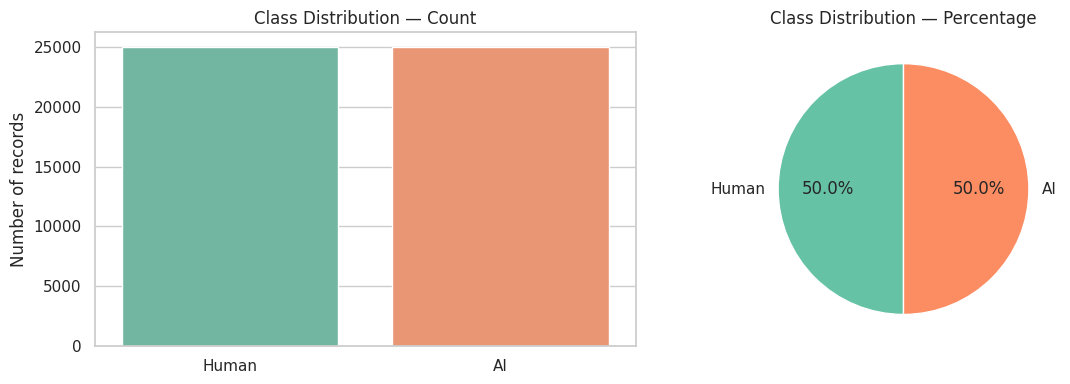

      Character_Count                  Word_Count                 \
                 mean  median      std       mean median     std   
Label                                                              
0             2160.66  1848.0  1412.91     282.27  244.0  174.39   
1             2340.83  2024.0  1470.70     283.99  246.0  175.55   

      Sentence_Count               Average_Word_Length               \
                mean median    std                mean median   std   
Label                                                                 
0              34.68   29.0  24.53                6.45   6.58  0.47   
1              33.48   29.0  22.07                7.18   7.23  0.26   

      Unique_Word_Ratio               
                   mean median   std  
Label                                 
0                  0.40   0.35  0.21  
1                  0.37   0.31  0.20  


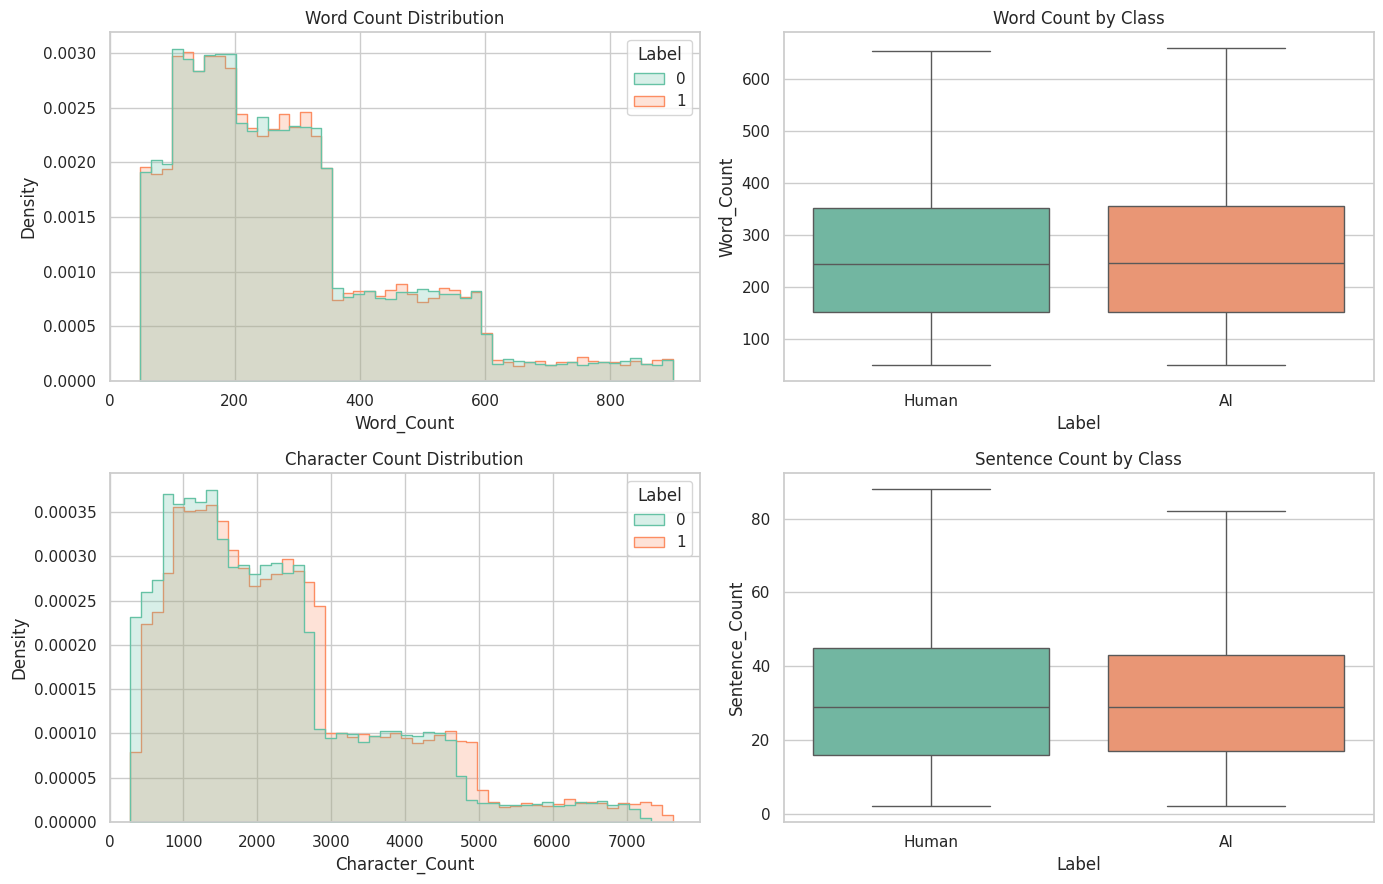

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (817 > 512). Running this sequence through the model will result in indexing errors


         count    mean     std   min    50%    90%    95%     99%     max
Label                                                                    
0      25000.0  384.72  245.17  58.0  331.0  744.0  844.0  1171.0  1279.0
1      25000.0  369.53  229.95  58.0  319.0  707.0  803.0  1103.0  1182.0
Over 128 tokens: 90.11%
Over 256 tokens: 62.23%
Over 512 tokens: 22.56%


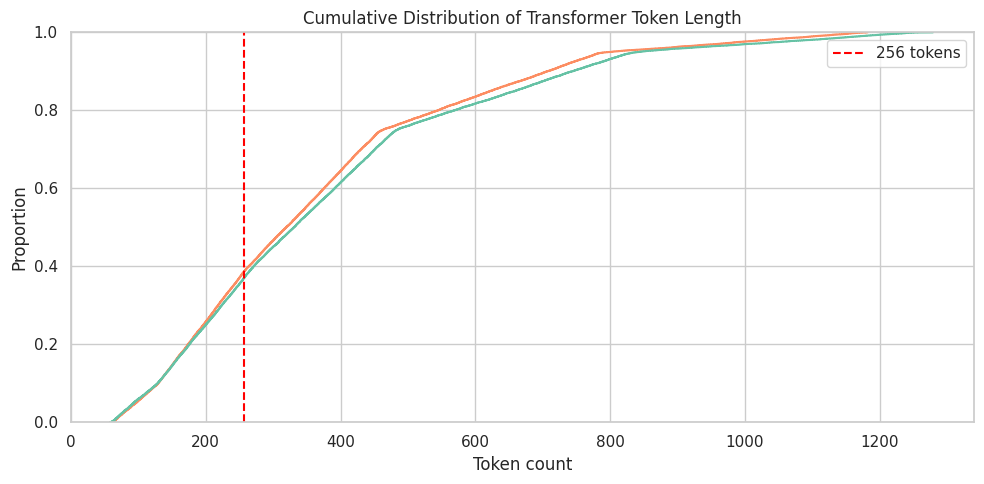

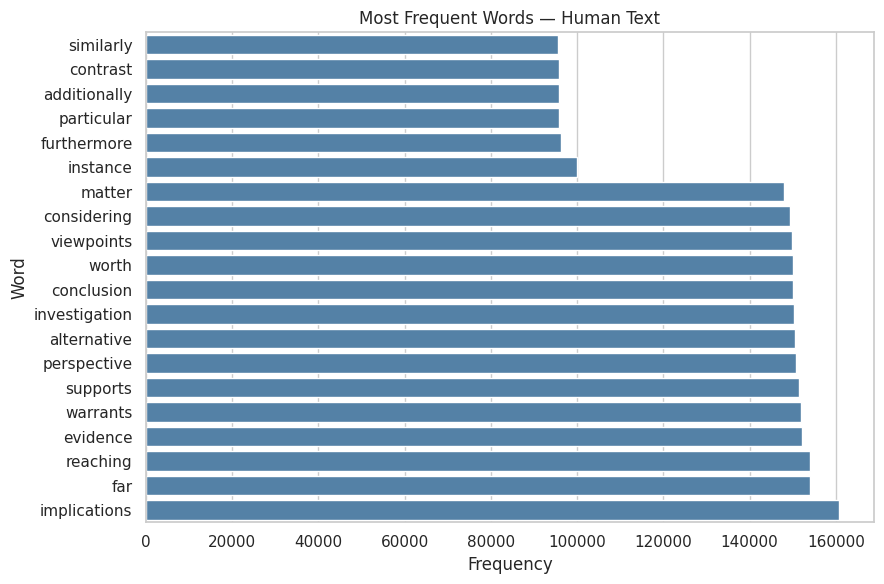

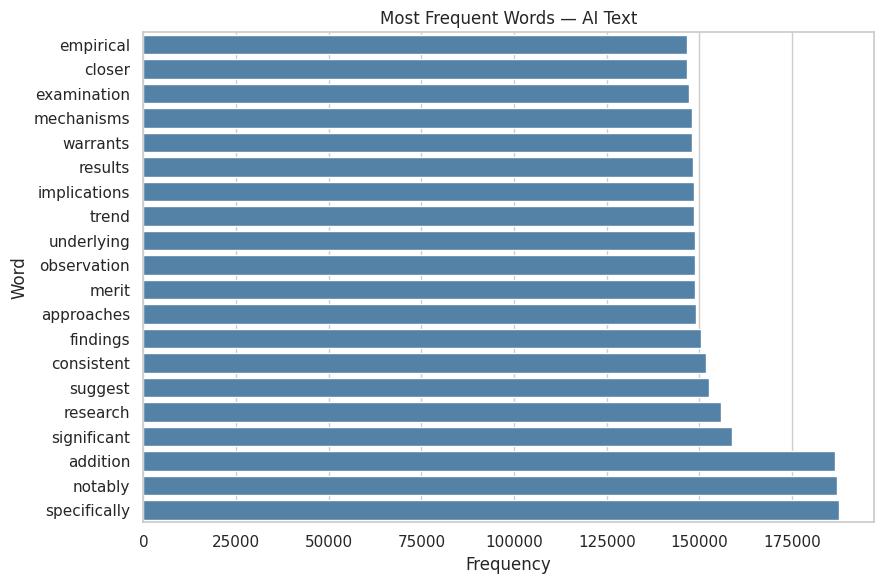

Conflicting normalized texts: 0
Human duplicate rate: 0.00%
AI duplicate rate: 0.00%
{
  "dataset_rows": 50000,
  "dataset_columns": [
    "Raw_Text",
    "Label"
  ],
  "missing_text": 0,
  "missing_labels": 0,
  "duplicate_rows": 0,
  "unique_labels": [
    "0",
    "1"
  ],
  "class_distribution": {
    "0": 25000,
    "1": 25000
  },
  "median_word_count_by_class": {
    "0": 244.0,
    "1": 246.0
  },
  "median_token_count_by_class": {
    "0": 331.0,
    "1": 319.0
  },
  "percentage_over_256_tokens": 62.232
}


In [22]:
## 3\. Complete EDA notebook

### Step 1 — Load and inspect the dataset

#This first step establishes the baseline before making any transformations.



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

df.columns = df.columns.str.strip()

# Validate schema
required_columns = {"Raw_Text", "Label"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

print("Shape:", df.shape)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 records:")
print(df.head())

print("\nRandom sample:")
print(df.sample(min(5, len(df)), random_state=42))

print("\nDescriptive statistics:")
print(df.describe(include="all").T)


#What to look for: unexpected columns, unusually short text, malformed records, and whether the dataset is large enough to support a meaningful train/validation/test split.

### Step 2 — Missing values and data quality


print("Missing values:")
print(df.isnull().sum())

print("\nMissing value percentage:")
print((df.isnull().mean() * 100).round(2))

print("\nExact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate text records:",
    df["Raw_Text"].dropna().duplicated().sum()
)

print("\nUnique labels:")
print(df["Label"].value_counts(dropna=False))

print("\nUnique label data types:")
print(df["Label"].map(lambda x: type(x).__name__).value_counts())

"""Investigate these issues before ETL:

- Missing text or labels.
- Duplicate text assigned to different labels.
- Exact duplicates that may cause train/test leakage.
- Unexpected label values beyond `0` and `1`.
- Text that consists only of whitespace.
"""
### Step 3 — Analyze the target variable



label_counts = df["Label"].value_counts().reindex([0, 1], fill_value=0)
label_pct = df["Label"].value_counts(normalize=True).reindex(
    [0, 1], fill_value=0
) * 100

label_summary = pd.DataFrame({
    "Count": label_counts,
    "Percentage": label_pct.round(2),
})

label_summary.index = ["Human (0)", "AI (1)"]
print(label_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    x=["Human", "AI"],
    y=label_counts.values,
    hue=["Human", "AI"],
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Class Distribution — Count")
axes[0].set_ylabel("Number of records")

axes[1].pie(
    label_counts.values,
    labels=["Human", "AI"],
    autopct="%1.1f%%",
    startangle=90,
)
axes[1].set_title("Class Distribution — Percentage")

plt.tight_layout()
plt.show()

"""Interpretation:

- A roughly balanced dataset provides a useful starting point.
- If one class dominates, accuracy alone can be misleading.
- Consider class-specific precision, recall, F1-score, and the confusion matrix.
- Do not automatically oversample or undersample; first establish a baseline and inspect the split strategy.
"""
### Step 4 — Engineer text features for analysis


eda = df.copy()

eda["Text"] = eda["Raw_Text"].fillna("").astype(str)

# Basic text features
eda["Character_Count"] = eda["Text"].str.len()

eda["Word_Count"] = eda["Text"].apply(
    lambda text: len(text.split())
)

eda["Sentence_Count"] = eda["Text"].apply(
    lambda text: len([
        sentence for sentence in
        __import__("re").split(r"[.!?]+", text)
        if sentence.strip()
    ])
)

eda["Average_Word_Length"] = eda["Text"].apply(
    lambda text: (
        np.mean([len(w) for w in text.split()])
        if text.split() else 0
    )
)

eda["Unique_Word_Ratio"] = eda["Text"].apply(
    lambda text: (
        len(set(text.lower().split())) / len(text.split())
        if text.split() else 0
    )
)

print(
    eda.groupby("Label")[
        [
            "Character_Count",
            "Word_Count",
            "Sentence_Count",
            "Average_Word_Length",
            "Unique_Word_Ratio",
        ]
    ].agg(["mean", "median", "std"]).round(2)
)

#These are descriptive features, not proof of authorship. AI and human texts can have very similar length, vocabulary, and sentence structure.

### Step 5 — Visualize text length distributions

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(
    data=eda,
    x="Word_Count",
    hue="Label",
    bins=50,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[0, 0],
)
axes[0, 0].set_title("Word Count Distribution")
axes[0, 0].set_xlim(left=0)

sns.boxplot(
    data=eda,
    x="Label",
    y="Word_Count",
    hue="Label",
    legend=False,
    showfliers=False,
    ax=axes[0, 1],
)
axes[0, 1].set_xticks([0, 1], ["Human", "AI"])
axes[0, 1].set_title("Word Count by Class")

sns.histplot(
    data=eda,
    x="Character_Count",
    hue="Label",
    bins=50,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Character Count Distribution")
axes[1, 0].set_xlim(left=0)

sns.boxplot(
    data=eda,
    x="Label",
    y="Sentence_Count",
    hue="Label",
    legend=False,
    showfliers=False,
    ax=axes[1, 1],
)
axes[1, 1].set_xticks([0, 1], ["Human", "AI"])
axes[1, 1].set_title("Sentence Count by Class")

plt.tight_layout()
plt.show()

#Interpretation questions:

"""- Are AI texts substantially longer than human texts?
- Does one class have many more very short examples?
- Are there extreme outliers or unusually long documents?
- Could text length alone be an unintended shortcut for classification?"""

#If the two classes have noticeably different length distributions, test your classifier on length-matched subsets as an additional robustness check.

### Step 6 — Examine text length in actual Transformer tokens

#Word count is not the same as Transformer token count. Since our baseline model uses a 256-token maximum, inspect how many records would be truncated.



from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Analyze a sample first to control memory usage on large datasets.
sample_texts = eda["Text"].tolist()

token_lengths = []
for text in sample_texts:
    token_ids = tokenizer(
        text,
        add_special_tokens=True,
        truncation=False,
    )["input_ids"]
    token_lengths.append(len(token_ids))

eda["Token_Count"] = token_lengths

print(
    eda.groupby("Label")["Token_Count"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(2)
)

for limit in [128, 256, 512]:
    print(
        f"Over {limit} tokens:",
        f"{(eda['Token_Count'] > limit).mean() * 100:.2f}%"
    )

plt.figure(figsize=(10, 5))
sns.ecdfplot(
    data=eda,
    x="Token_Count",
    hue="Label",
)
plt.axvline(256, color="red", linestyle="--", label="256 tokens")
plt.xlim(left=0)
plt.title("Cumulative Distribution of Transformer Token Length")
plt.xlabel("Token count")
plt.legend()
plt.tight_layout()
plt.show()


### Step 7 — Explore common words by class




from sklearn.feature_extraction.text import CountVectorizer

def plot_common_words(data, label, title, top_n=20):
    texts = data.loc[data["Label"] == label, "Text"].tolist()

    if not texts:
        print(f"No records for label {label}")
        return

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=10000,
        min_df=2,
        ngram_range=(1, 1),
    )

    matrix = vectorizer.fit_transform(texts)
    frequencies = np.asarray(matrix.sum(axis=0)).ravel()

    terms = vectorizer.get_feature_names_out()
    top_indices = np.argsort(frequencies)[-top_n:]

    word_df = pd.DataFrame({
        "Word": terms[top_indices],
        "Frequency": frequencies[top_indices],
    }).sort_values("Frequency")

    plt.figure(figsize=(9, 6))
    sns.barplot(
        data=word_df,
        x="Frequency",
        y="Word",
        color="steelblue",
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_common_words(eda, 0, "Most Frequent Words — Human Text")
plot_common_words(eda, 1, "Most Frequent Words — AI Text")


### Step 8 — Check duplicate text and conflicting labels

#This is one of the most important steps before splitting the dataset.

# Normalize whitespace and casing for duplicate investigation only.
eda["Text_Normalized"] = (
    eda["Text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Find normalized texts associated with multiple labels.
label_counts = eda.groupby("Text_Normalized")["Label"].nunique()
conflicting_texts = label_counts[label_counts > 1].index

print("Conflicting normalized texts:", len(conflicting_texts))

if len(conflicting_texts):
    print(
        eda[eda["Text_Normalized"].isin(conflicting_texts)][
            ["Raw_Text", "Label"]
        ].head(20)
    )

# Measure duplicate rates by class.
for label, name in [(0, "Human"), (1, "AI")]:
    subset = eda.loc[eda["Label"] == label, "Text_Normalized"]
    print(
        f"{name} duplicate rate:",
        f"{subset.duplicated().mean() * 100:.2f}%"
        if len(subset) else "No records"
    )

## 4\. Create an EDA summary report

eda_report = {
    "dataset_rows": int(len(df)),
    "dataset_columns": df.columns.tolist(),
    "missing_text": int(df["Raw_Text"].isna().sum()),
    "missing_labels": int(df["Label"].isna().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "unique_labels": [
        str(x) for x in df["Label"].dropna().unique()
    ],
    "class_distribution": {
        str(k): int(v)
        for k, v in df["Label"].value_counts().items()
    },
    "median_word_count_by_class": {
        str(k): float(v)
        for k, v in eda.groupby("Label")["Word_Count"].median().items()
    },
    "median_token_count_by_class": {
        str(k): float(v)
        for k, v in eda.groupby("Label")["Token_Count"].median().items()
    },
    "percentage_over_256_tokens": float(
        (eda["Token_Count"] > 256).mean() * 100
    ),
}

import json

with open("eda_report.json", "w", encoding="utf-8") as file:
    json.dump(eda_report, file, indent=2)

print(json.dumps(eda_report, indent=2))


## 5\. How EDA informs your ETL and model

| EDA finding | Recommended action |
| --- | --- |
| Missing text or labels | Reject and record invalid rows |
| Conflicting labels | Investigate annotation quality |
| Many duplicate texts | Deduplicate and prevent split leakage |
| Imbalanced classes | Use appropriate metrics; consider class weighting if needed |
| Long texts | Choose token length based on token-count percentiles |
| Large length differences by class | Evaluate a length-matched test subset |
| Topic or source differences | Use source-held-out evaluation |
| Strong overlap in text patterns | Check near-duplicates and prompt leakage |

# Will Complete EDA first, then finalize ETL, then split the cleaned dataset and fine-tune DistilBERT. Keep the held-out test set untouched until model selection is complete.



In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)


In [24]:
# 1. Reproducibility
set_seed(42)

# 2. Load dataset
df = pd.read_csv(
    "AI_vs_Human_Text_Classification_Benchmark.csv"
)
df.columns = df.columns.str.strip()

df = df[["Raw_Text", "Label"]].dropna().copy()
df = df.rename(columns={"Raw_Text": "text", "Label": "label"})

df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 0]
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)

# Verify confirmed labels
assert set(df["label"].unique()) == {0, 1}, (
    "Expected labels: 0 = Human, 1 = AI"
)

# Inspect and remove duplicate text with conflicting labels
conflicts = df.groupby("text")["label"].nunique()
conflicts = conflicts[conflicts > 1]

print("Conflicting texts:", len(conflicts))
if len(conflicts):
    raise ValueError(
        "Resolve conflicting labels before model training."
    )

df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nLabel counts:")
print(df["label"].value_counts().sort_index())

# 3. Split into train / validation / test
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"],
)

print("\nSplit sizes:", len(train_df), len(val_df), len(test_df))

# 4. Load pretrained model and tokenizer
MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "HUMAN", 1: "AI"},
    label2id={"HUMAN": 0, "AI": 1},
)

# 5. Tokenize the data
def tokenize_data(frame):
    ds = Dataset.from_pandas(
        frame[["text", "label"]].reset_index(drop=True)
    )

    return ds.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
        ),
        batched=True,
        remove_columns=["text"],
    )

train_ds = tokenize_data(train_df)
val_ds = tokenize_data(val_df)
test_ds = tokenize_data(test_df)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

# 6. Evaluation metrics
def compute_metrics(eval_pred):
    logits, y_true = eval_pred

    # Numerically stable softmax
    logits = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(logits)
    probabilities = exp_logits / exp_logits.sum(
        axis=1, keepdims=True
    )

    y_prob_ai = probabilities[:, 1]
    y_pred = (y_prob_ai >= 0.5).astype(int)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            pos_label=1,
            zero_division=0,
        )
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "ai_precision": precision,
        "ai_recall": recall,
        "ai_f1": f1,
        "roc_auc": roc_auc_score(y_true, y_prob_ai),
    }

# 7. Configure training
training_args = TrainingArguments(
    output_dir="./ai_human_results",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="ai_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

# 8. Train
trainer.train()

# 9. Evaluate on the held-out test set
pred_output = trainer.predict(test_ds)
logits = pred_output.predictions
y_true = pred_output.label_ids

logits = logits - logits.max(axis=1, keepdims=True)
exp_logits = np.exp(logits)
probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)

y_prob_ai = probs[:, 1]
y_pred = (y_prob_ai >= 0.5).astype(int)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Human", "AI"],
    digits=4,
    zero_division=0,
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("Test ROC-AUC:", roc_auc_score(y_true, y_prob_ai))

# 10. Save model
trainer.save_model("./ai_human_detector")
tokenizer.save_pretrained("./ai_human_detector")

print("\nModel saved to ./ai_human_detector")

Conflicting texts: 0
Dataset shape: (50000, 2)

Label counts:
label
0    25000
1    25000
Name: count, dtype: int64

Split sizes: 40000 5000 5000


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Classification report:
              precision    recall  f1-score   support

       Human     1.0000    1.0000    1.0000      2500
          AI     1.0000    1.0000    1.0000      2500

    accuracy                         1.0000      5000
   macro avg     1.0000    1.0000    1.0000      5000
weighted avg     1.0000    1.0000    1.0000      5000

Confusion matrix:
[[2500    0]
 [   0 2500]]
Test ROC-AUC: 1.0


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to ./ai_human_detector


In [25]:
import os

saved_path = "./ai_human_detector"
if os.path.exists(saved_path):
    print(f"Checking files in '{saved_path}':")
    for file in os.listdir(saved_path):
        print(f" - {file}")
else:
    print(f"Directory '{saved_path}' does not exist. Please ensure training completed successfully.")

Checking files in './ai_human_detector':
 - tokenizer_config.json
 - tokenizer.json
 - config.json
 - training_args.bin
 - model.safetensors


In [26]:
save the train model

'train model' was not found in history, as a file, url, nor in the user namespace.


In [27]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load the saved model and tokenizer
model_path = "./ai_human_detector"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

# Create a text classification pipeline
detector = pipeline("text-classification", model=model, tokenizer=tokenizer)

# Test with sample texts
samples = [
    "I went to the store today and bought some apples. The weather was nice and I enjoyed my walk.",
    "Within the context of artificial intelligence, several overlapping paradigms present key methodologies for optimized execution."
]

for text in samples:
    result = detector(text)[0]
    print(f"Text: {text}\nPredicted Label: {result['label']} (Confidence: {result['score']:.4f})\n")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Text: I went to the store today and bought some apples. The weather was nice and I enjoyed my walk.
Predicted Label: HUMAN (Confidence: 0.9953)

Text: Within the context of artificial intelligence, several overlapping paradigms present key methodologies for optimized execution.
Predicted Label: AI (Confidence: 0.9999)



In [28]:
import pandas as pd
import numpy as np

# Create a DataFrame for test set analysis
# Since we mapped test_ds directly from test_df, we can use test_df texts
test_analysis = pd.DataFrame({
    'Text': test_df['text'].values,
    'True_Label': y_true,
    'Predicted_Label': y_pred,
    'AI_Probability': y_prob_ai
})

# Identify misclassified samples
misclassified = test_analysis[test_analysis['True_Label'] != test_analysis['Predicted_Label']].copy()

# Calculate confidence score
misclassified['Confidence'] = np.where(
    misclassified['Predicted_Label'] == 1,
    misclassified['AI_Probability'],
    1 - misclassified['AI_Probability']
)

print(f"Total misclassified samples in the test set: {len(misclassified)} out of {len(test_df)}")
print(f"Error Rate: {len(misclassified) / len(test_df) * 100:.2f}%")

# Separate False Positives and False Negatives
false_positives = misclassified[misclassified['True_Label'] == 0]
false_negatives = misclassified[misclassified['True_Label'] == 1]

print(f"False Positives (Human predicted as AI): {len(false_positives)}")
print(f"False Negatives (AI predicted as Human): {len(false_negatives)}\n")

print("=== Sample False Positives (Human predicted as AI) ===")
for idx, row in false_positives.head(3).iterrows():
    print(f"Confidence: {row['Confidence']:.4f}")
    print(f"Text snippet: {row['Text'][:300]}...\n")

print("=== Sample False Negatives (AI predicted as Human) ===")
for idx, row in false_negatives.head(3).iterrows():
    print(f"Confidence: {row['Confidence']:.4f}")
    print(f"Text snippet: {row['Text'][:300]}...\n")

Total misclassified samples in the test set: 0 out of 5000
Error Rate: 0.00%
False Positives (Human predicted as AI): 0
False Negatives (AI predicted as Human): 0

=== Sample False Positives (Human predicted as AI) ===
=== Sample False Negatives (AI predicted as Human) ===


In [29]:
import shutil
from google.colab import files

# Zip the saved model directory
shutil.make_archive('ai_human_detector', 'zip', './ai_human_detector')
print("Model zipped successfully as 'ai_human_detector.zip'.")

# Trigger browser download of the zip file
files.download('ai_human_detector.zip')

Model zipped successfully as 'ai_human_detector.zip'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>